### aim 1 figure 3 - was originally aim2 fig2.

In [1]:
%logstart -r aim1_fig3.py 

Activating auto-logging. Current session state plus future input saved.
Filename       : aim2_fig2.py
Mode           : backup
Output logging : False
Raw input log  : True
Timestamping   : False
State          : active


In [2]:
# Set parameters/variables:
project_path = '/project_data/volume0/tpirnia/data/EEGWS'
results_path = '/data/across_subjects/results/clean/aim-2/'

c_dfname = 'results_c_avg_w1000_block5-5_ridge-CLEAN.csv'
r_dfname = 'results_c_avg_w1000_block5-5_ridge_r-CLEAN.csv'

datafiles = {'cue-locked':
             {'fname':c_dfname,
              't_start':0,
             },
             'response-locked':
             {'fname':r_dfname,
              't_start':-500,
             },
            }
exclude_subjects = ['EP24']

figure_name = 'Figure3-Comparison_of_cue_and_response_locked.png'

ttest_fname = project_path + '/data/across_subjects/results/clean/ttest.csv'


In [3]:
# Import functions:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits import axes_grid1
from matplotlib import colors
import matplotlib as mpl
import seaborn as sns
from scipy.stats import ttest_rel


In [4]:
sys.path.append(project_path + '/maybe_repo')
from utils.utils import save_output


In [5]:
# Figure parameters:
plt.rcParams.update(plt.rcParamsDefault)
%matplotlib inline
plt.style.use('seaborn-darkgrid')
plt.style.use('seaborn-poster')


In [6]:
# Load data files:
main_df = []
for _lock in datafiles:
    # load file
    _df = pd.read_csv((project_path
                          + results_path
                          + datafiles[_lock]['fname']),
                     )
    # create c vs r column
    _df['Alignment'] = _lock
    _df['t_start'] = datafiles[_lock]['t_start']
    
    new_col = 'test_accuracy'
    old_col = ('t_' + str(datafiles[_lock]['t_start'] + 500))
    _df.rename(columns={old_col:new_col},
                   inplace=True)
    # add to list
    main_df.append(_df)

# Concatenate dataframes:
main_df = pd.concat(main_df,
                    ignore_index=True)
main_df.reset_index(inplace=True, 
                    drop=True)


In [7]:
# Update column names:
col_renames={'subject': 'Subject',
             'classifier':'Classifier', 
             'window': 'Trial Length',
             'train_accuracy':'Train Accuracy', 
             'test_accuracy': 'Test Accuracy',
            }
main_df.rename(columns=col_renames,
               inplace=True)


In [8]:
# Remove excluded subjects
main_df = main_df[~main_df['Subject'].isin(exclude_subjects)]
main_df.reset_index(inplace=True,
                    drop=True)


In [9]:
# change column to types and update categories
# - for subjects:
subjects = main_df['Subject'].unique()
_cattype = pd.api.types.CategoricalDtype(categories=subjects, 
                                         ordered=True)
main_df['Subject']=main_df['Subject'].astype(_cattype)

# - for Classifier
clfs = {'ridge':'Ridge Classifer',}
for _c in clfs:
    _inds = (main_df['Classifier'] == _c)
    main_df.loc[_inds,'Classifier'] = clfs[_c]

_cattype = pd.api.types.CategoricalDtype(categories=list(clfs.values()),
                                         ordered=True)
main_df['Classifier'] = main_df['Classifier'].astype(_cattype)


In [12]:
# Make (melt) dataframe for train/test classification 
trte_df = main_df.melt(id_vars=['Subject',
                            'Classifier',
                            'Alignment',
                            't_start',
                            'Trial Length',
                            'step',
                            'w_train'],
                   var_name='Performance',
                   value_name='Accuracy')

_inds_tr, _inds_te = (trte_df['Performance'] == 'Train Accuracy'),(trte_df['Performance'] == 'Test Accuracy')
trte_df.loc[_inds_tr,'Performance'] = 'Train'
trte_df.loc[_inds_te,'Performance'] = 'Test'


In [13]:
main_df.head()

,Subject,Classifier,Trial Length,step,w_train,Train Accuracy,Test Accuracy,Alignment,t_start
0,EP03,Ridge Classifer,1000,0,0,0.665000,0.666667,cue-locked,0
1,EP05,Ridge Classifer,1000,0,0,0.578333,0.650000,cue-locked,0
2,EP06,Ridge Classifer,1000,0,0,0.721667,0.716667,cue-locked,0
3,EP07,Ridge Classifer,1000,0,0,0.933333,0.916667,cue-locked,0
4,EP09,Ridge Classifer,1000,0,0,0.583333,0.616667,cue-locked,0


In [14]:
trte_df.head()

,Subject,Classifier,Alignment,t_start,Trial Length,step,w_train,Performance,Accuracy
0,EP03,Ridge Classifer,cue-locked,0,1000,0,0,Train,0.665000
1,EP05,Ridge Classifer,cue-locked,0,1000,0,0,Train,0.578333
2,EP06,Ridge Classifer,cue-locked,0,1000,0,0,Train,0.721667
3,EP07,Ridge Classifer,cue-locked,0,1000,0,0,Train,0.933333
4,EP09,Ridge Classifer,cue-locked,0,1000,0,0,Train,0.583333


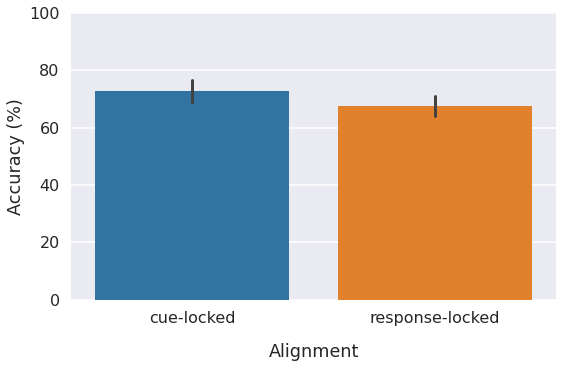

In [15]:
# Train Accuracy per classifier for full trial length (cue to 1000ms)
_figdims = (8.7, 5.27)
_fig, _ax = plt.subplots(figsize=_figdims)
_g = sns.barplot(y='Test Accuracy',
                 x='Alignment',
                 data=main_df,
                 ax=_ax, 
                 errwidth=3,
                 ci=95)


_ax.xaxis.labelpad = 17

locs, _ = plt.yticks()
_ax.set(ylabel='Accuracy (%)', 
        ylim=[0,1],
        yticks=locs, 
        yticklabels=list(map(int,locs*100)),)
plt.savefig((project_path 
             + results_path 
             + figure_name),
            dpi=450, 
            bbox_inches = "tight")
plt.show()

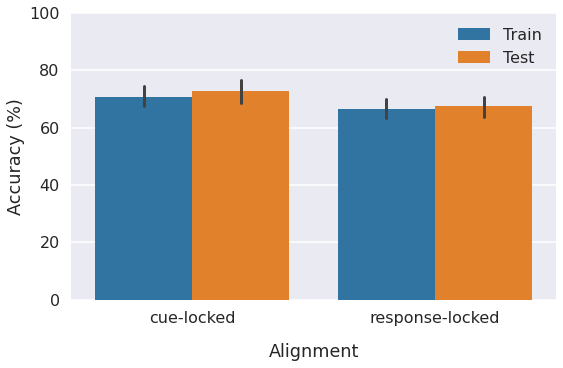

In [16]:
# Train and test Accuracy per classifier for full trial length (cue to 1000ms)
_figdims = (8.7, 5.27)
_fig, _ax = plt.subplots(figsize=_figdims)
_g = sns.barplot(y='Accuracy',
                 x='Alignment',
                 hue='Performance',
                 data=trte_df,
                 ax=_ax, 
                 errwidth=3,
                 ci=95)


_ax.xaxis.labelpad = 17

locs, _ = plt.yticks()
_ax.set(ylabel='Accuracy (%)', 
        ylim=[0,1],
        yticks=locs, 
        yticklabels=list(map(int,locs*100)),)
plt.gca().legend().set_title('')
plt.savefig((project_path 
             + results_path 
             + figure_name[:-4]
             + '_traintest.png'),
            dpi=450, 
            bbox_inches = "tight")
plt.show()


In [17]:
# make df of descriptive statistics
stat_df = main_df.drop(columns=['step',
                                'w_train',
                                'Classifier',
                                't_start', 
                                'Trial Length'
                               ],
                      ).groupby(by=('Alignment'),
                               ).agg(['min', 'max','mean','std','sem','var']) * 100
print(stat_df)
print(stat_df.drop(columns=['min','max','sem','var'],level=1).transpose().to_latex(float_format="%.2f"))

                Train Accuracy                                            \
                           min        max       mean       std       sem   
Alignment                                                                  
cue-locked           55.500000  93.333333  70.845238  9.755122  1.843545   
response-locked      51.333333  92.666667  66.601190  8.770079  1.657389   

                          Test Accuracy                                   \
                      var           min        max       mean        std   
Alignment                                                                  
cue-locked       0.951624     56.666667  91.666667  72.678571  10.396851   
response-locked  0.769143     48.333333  91.666667  67.440476  10.035761   

                                    
                     sem       var  
Alignment                           
cue-locked       1.96482  1.080945  
response-locked  1.89658  1.007165  
\begin{tabular}{llrr}
\toprule
              & Alignm

In [18]:

# T-test by trial length:
c_lock = main_df['Test Accuracy'][main_df['Alignment']=='cue-locked'].values
r_lock = main_df['Test Accuracy'][main_df['Alignment']=='response-locked'].values



t_crlocked = ttest_rel(c_lock, r_lock)

rnd_fn = lambda x: np.round(x, decimals=2)
print('Cue v. Response-locked:',
      [rnd_fn(t_crlocked[0]),np.round(t_crlocked[1],decimals=8)])


Cue v. Response-locked: [1.97, 0.05913044]


In [19]:
save_output(ttest_fname, ['cue-locked','response-locked']+ list(t_crlocked), header=['group-1', 'group-2','t-statistic','p-value'],sep=',')

In [20]:
# Save output as a temporary notebook data csv
main_df_out = project_path + '/data/across_subjects/results/tmp_notebook_data/aim2_fig2_main_df.csv'
main_df.to_csv(main_df_out, index=False)

%load_ext autoreload
%autoreload 1 

%reload_ext autoreload

sep=','
'\n'+sep.join(map(np.str, ['cue-locked','response-locked']+ list(t_crlocked)))

from filelock import FileLock

def fill_path(fname):
    if not os.path.exists(os.path.dirname(fname)): 
        os.makedirs(os.path.dirname(fname), exist_ok=True)
        
def format_stats(x):
    if isinstance(x,type(dict())): 
        x=str(np.nan)
    return str(x)   

def save_output(fname, results, header=None,sep='\t'):
    fill_path(fname)
    out_ = '\n'+ sep.join(map(format_stats, results))
    if header:
        out_ = sep.join(map(format_stats, header)) + out_
    with FileLock(fname + ".lock"): 
        with open(fname, "a+") as f:  _ = f.write(out_)

def fill_path(fname):
    if not os.path.exists(os.path.dirname(fname)): 
        os.makedirs(os.path.dirname(fname), exist_ok=True)
        
    group_fname = (arg.project_path 
                   + 'data/across_subjects/results/TG_across_subjects/'
                   + arg.subject 
                   + '/'
                   + arg.out_name 
                   + '.csv')
    with FileLock(group_fname+".lock"): 
        header=False
        if not os.path.exists(group_fname): 
            header=True
        with open(group_fname, "a+") as f:  
            acc_agg.to_csv(f, header=header, index=False)